In [1]:
import glob, pickle, os
import pandas as pd
import numpy as np

In [2]:
Fs = 3e4
out_path = './dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/'

files_to_analyze = glob.glob(out_path + '*_EncodingModel.pickle')

In [3]:
files_to_analyze

['./dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2\\m23_unit_1_EncodingModel.pickle',
 './dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2\\m29_unit_1_EncodingModel.pickle',
 './dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2\\m30_unit_1_EncodingModel.pickle',
 './dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2\\m31_unit_1_EncodingModel.pickle',
 './dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2\\m31_unit_2_EncodingModel.pickle',
 './dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2\\m31_unit_3_EncodingModel.pickle']

In [4]:
deg_amp, volt_amp = [], []     # max-magnitude deflection per unit

av_max = []
av_max_bin = []
local_max = []
local_max_bin_pre = []
local_max_bin_post = []
mothID = []

for fp in files_to_analyze:
    ID = "_".join(os.path.basename(fp).split('_')[0:3])
    mothID.append(ID)
    print(f'working on {ID}')
    
    fname = os.path.basename(fp)
    with open(fp, 'rb') as f:
        data = pickle.load(f)
        p_spike = np.asarray(data[13]).ravel()    # index 1 = STA
        bins = np.asarray(data[12]).ravel()
        
        derivatives = np.gradient(p_spike, bins)
        max_steepness_idx = np.argmax(derivatives)
        max_steepness = derivatives[max_steepness_idx]
        
        av_max.append(max_steepness)
        av_max_bin.append(bins[max_steepness_idx])
        
        print(f"Max steepness: {max_steepness}")
        print(f"At bin: {bins[max_steepness_idx]}")

        # Also let's check consecutive differences just in case we want the local point-to-point max slope
        dx = np.diff(bins)
        dp = np.diff(p_spike)
        slopes = dp / dx
        max_slope_idx = np.argmax(slopes)
        
        local_max.append(slopes[max_slope_idx])
        local_max_bin_pre = bins[max_slope_idx]
        local_max_bin_post = bins[max_slope_idx+1]
        print(f"Max point-to-point slope: {slopes[max_slope_idx]} between {bins[max_slope_idx]} and {bins[max_slope_idx+1]}")

data = pd.DataFrame({'mothID': mothID, 
                    'av_max': av_max,
                     'av_max_bin': av_max_bin,
                     'local_max': local_max,
                     'local_max_bin_pre': local_max_bin_pre,
                     'local_max_bin_post': local_max_bin_post
                    })

working on m23_unit_1
Max steepness: 0.005399529691547327
At bin: 1.3921981848061877
Max point-to-point slope: 0.005425340146612838 between 1.3921981848061877 and 1.8875441565492812
working on m29_unit_1
Max steepness: 0.004797844325568826
At bin: 2.027276713825413
Max point-to-point slope: 0.0049698537217346 between 1.5617150364896122 and 2.027276713825413
working on m30_unit_1
Max steepness: 0.003175677106383189
At bin: 1.639674029158945
Max point-to-point slope: 0.004004748347901601 between 1.2017391425622117 and 1.639674029158945
working on m31_unit_1
Max steepness: 0.0019984693828655154
At bin: 0.1031780452133022
Max point-to-point slope: 0.0020812840785798454 between 0.1031780452133022 and 0.5360827427886505
working on m31_unit_2
Max steepness: 0.004269731842718029
At bin: 2.3713819863465604
Max point-to-point slope: 0.004269731842718029 between 1.9295014585651122 and 2.3713819863465604
working on m31_unit_3
Max steepness: 0.0005077330011804299
At bin: 0.9168068701712269
Max poin

In [5]:
data

,mothID,av_max,av_max_bin,local_max,local_max_bin_pre,local_max_bin_post
0,m23_unit_1,0.005400,1.392198,0.005425,0.491388,0.916807
1,m29_unit_1,0.004798,2.027277,0.004970,0.491388,0.916807
2,m30_unit_1,0.003176,1.639674,0.004005,0.491388,0.916807
3,m31_unit_1,0.001998,0.103178,0.002081,0.491388,0.916807
4,m31_unit_2,0.004270,2.371382,0.004270,0.491388,0.916807
5,m31_unit_3,0.000508,0.916807,0.000517,0.491388,0.916807


{'whiskers': [<matplotlib.lines.Line2D at 0x2e1299f3680>,
 'caps': [<matplotlib.lines.Line2D at 0x2e1299f3c50>,
 'boxes': [<matplotlib.lines.Line2D at 0x2e1299f3380>],
 'medians': [<matplotlib.lines.Line2D at 0x2e129a2c2c0>],
 'fliers': [<matplotlib.lines.Line2D at 0x2e129a2c5f0>],
 'means': []}

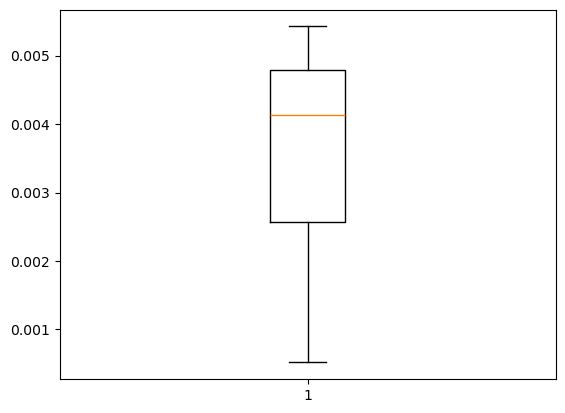

In [6]:
import matplotlib.pyplot as plt

plt.boxplot(data['local_max'])

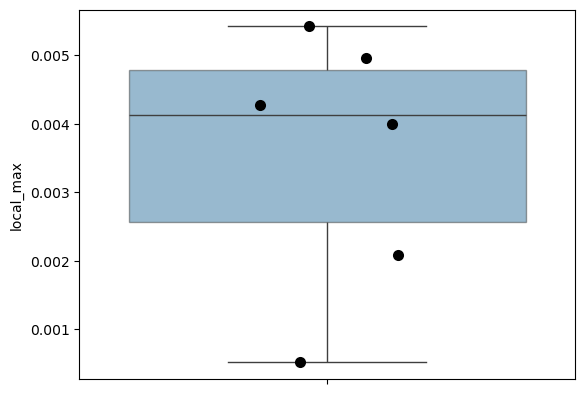

In [8]:
import seaborn as sns

# 1. Create the box plot (hide default outlier fliers)
sns.boxplot(data=data, y="local_max", boxprops=dict(alpha=0.5))

# 2. Overlay the individual data points
sns.stripplot(data=data, y="local_max", color="black", size=8, jitter=0.2)

# Show the visualization
plt.show()